In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# **Loading the dataset**

In [2]:
df = pd.read_csv('/content/sales_dataset.csv')

In [3]:
df.head()

,order_id,order_date,product,category,region,quantity,unit_price,total_sales
0,ORD-0001,2025-03-21,Bedsheet Set,Home,Central,3,1519,4557
1,ORD-0002,2025-04-06,Headphones,Electronics,West,5,1890,9450
2,ORD-0003,2025-01-24,Bedsheet Set,Home,East,5,1599,7995
3,ORD-0004,2025-05-22,Pen Set,Stationery,East,4,189,756
4,ORD-0005,2025-02-11,Jeans,Clothing,East,1,1574,1574


In [4]:
df.tail()

,order_id,order_date,product,category,region,quantity,unit_price,total_sales
148,ORD-0149,2025-05-30,Keyboard,Electronics,Central,4,1200,4800
149,ORD-0150,2025-02-13,Keyboard,Electronics,West,4,1140,4560
150,ORD-0025,2025-01-17,Wireless Mouse,Electronics,West,4,650,2600
151,ORD-0078,2025-02-05,Wireless Mouse,Electronics,Central,1,618,618
152,ORD-0122,2025-06-27,Water Bottle,Home,Central,5,379,1895


In [5]:
df.shape

(153, 8)

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 153 entries, 0 to 152
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   order_id     153 non-null    object
 1   order_date   153 non-null    object
 2   product      153 non-null    object
 3   category     153 non-null    object
 4   region       149 non-null    object
 5   quantity     153 non-null    int64 
 6   unit_price   153 non-null    int64 
 7   total_sales  153 non-null    int64 
dtypes: int64(3), object(5)
memory usage: 9.7+ KB


In [8]:
df.describe()

,quantity,unit_price,total_sales
count,153.000000,153.000000,153.000000
mean,3.000000,1250.660131,3784.875817
std,1.486784,788.362703,3187.957860
min,1.000000,114.000000,114.000000
25%,2.000000,522.000000,1350.000000
50%,3.000000,1200.000000,2400.000000
75%,4.000000,1804.000000,5700.000000
max,5.000000,2939.000000,13295.000000


In [7]:
# checking the missing values in dataset
df.isnull().sum()

,0
order_id,0
order_date,0
product,0
category,0
region,4
quantity,0
unit_price,0
total_sales,0


In [13]:
df.duplicated().sum()

np.int64(3)

In [14]:
df.drop_duplicates(inplace=True)

In [16]:
print("Dataset shape:", df.shape)
print("Duplicate records:", df.duplicated().sum())

Dataset shape: (150, 8)
Duplicate records: 0


In [18]:
df['region'] = df['region'].fillna('Unknown')

In [19]:
df.isnull().sum()

,0
order_id,0
order_date,0
product,0
category,0
region,0
quantity,0
unit_price,0
total_sales,0


In [20]:
df["order_date"] = pd.to_datetime(df["order_date"])

In [21]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 150 entries, 0 to 149
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   order_id     150 non-null    object        
 1   order_date   150 non-null    datetime64[ns]
 2   product      150 non-null    object        
 3   category     150 non-null    object        
 4   region       150 non-null    object        
 5   quantity     150 non-null    int64         
 6   unit_price   150 non-null    int64         
 7   total_sales  150 non-null    int64         
dtypes: datetime64[ns](1), int64(3), object(4)
memory usage: 10.5+ KB


# **Data Analysis using Pandas.**

In [25]:
category_sales = df.groupby("category")["total_sales"].sum()

print(category_sales)

category
Clothing       191739
Electronics    233590
Home           137128
Stationery      11516
Name: total_sales, dtype: int64


In [26]:
category_sales = category_sales.sort_values(ascending=False)

print(category_sales)

category
Electronics    233590
Clothing       191739
Home           137128
Stationery      11516
Name: total_sales, dtype: int64


In [27]:
product_sales = df.groupby("product")["total_sales"].sum()

product_sales = product_sales.sort_values(ascending=False)

print(product_sales)

product
USB-C Hub         98880
Bedsheet Set      79150
Hoodie            73586
Sneakers          71794
Headphones        63450
Keyboard          55980
Jeans             38450
Storage Box       25965
Desk Lamp         22078
Wireless Mouse    15280
Water Bottle       9935
T-Shirt            7909
Desk Organizer     4050
Planner            2930
Notebook           2520
Pen Set            2016
Name: total_sales, dtype: int64


In [28]:
region_sales = df.groupby("region")["total_sales"].sum()

region_sales = region_sales.sort_values(ascending=False)

print(region_sales)

region
North      167843
West       118955
Central     98019
East        93719
South       83820
Unknown     11617
Name: total_sales, dtype: int64


In [29]:
monthly_sales = df.groupby(
    df["order_date"].dt.to_period("M")
)["total_sales"].sum()

monthly_sales = monthly_sales.sort_index()

print(monthly_sales)

order_date
2025-01     66958
2025-02     61598
2025-03    144474
2025-04    103878
2025-05     99501
2025-06     97564
Freq: M, Name: total_sales, dtype: int64


# ***DATA VISUALIZATION***

# Bar Chart

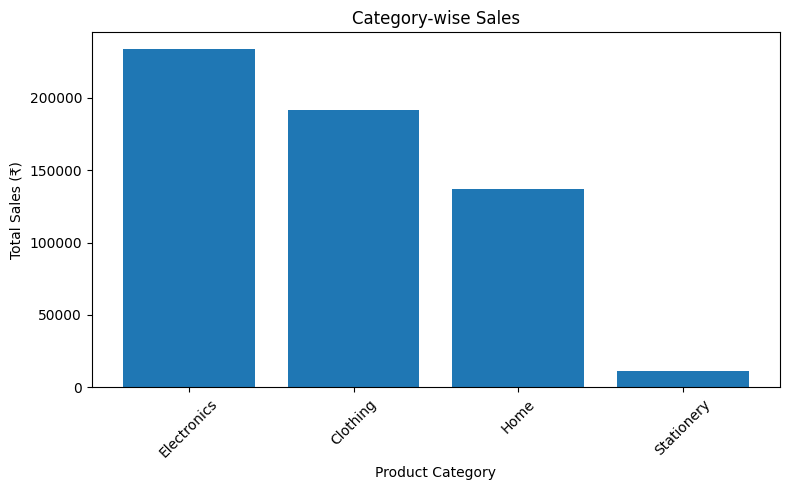

In [30]:
plt.figure(figsize=(8, 5))

plt.bar(category_sales.index, category_sales.values)

plt.title("Category-wise Sales")
plt.xlabel("Product Category")
plt.ylabel("Total Sales (₹)")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

# **Line Chart**

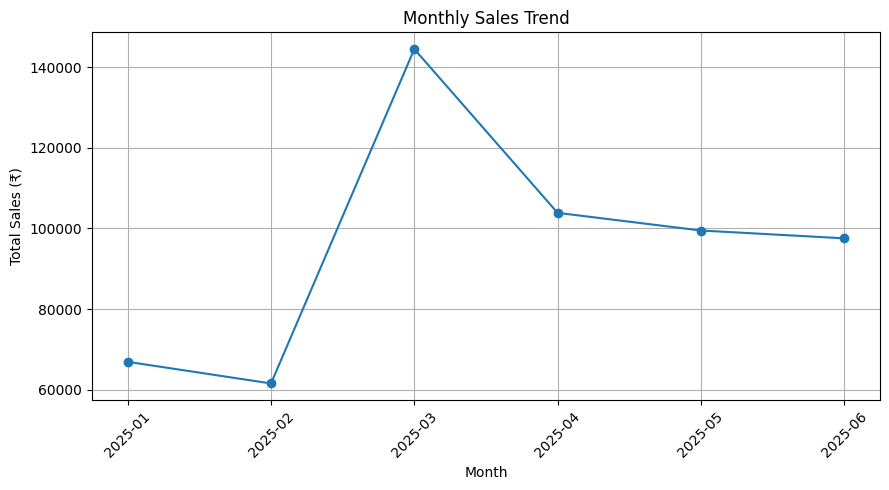

In [31]:
plt.figure(figsize=(9, 5))

plt.plot(
    monthly_sales.index.astype(str),
    monthly_sales.values,
    marker="o"
)

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales (₹)")

plt.xticks(rotation=45)

plt.grid(True)
plt.tight_layout()
plt.show()

# **pie chart**

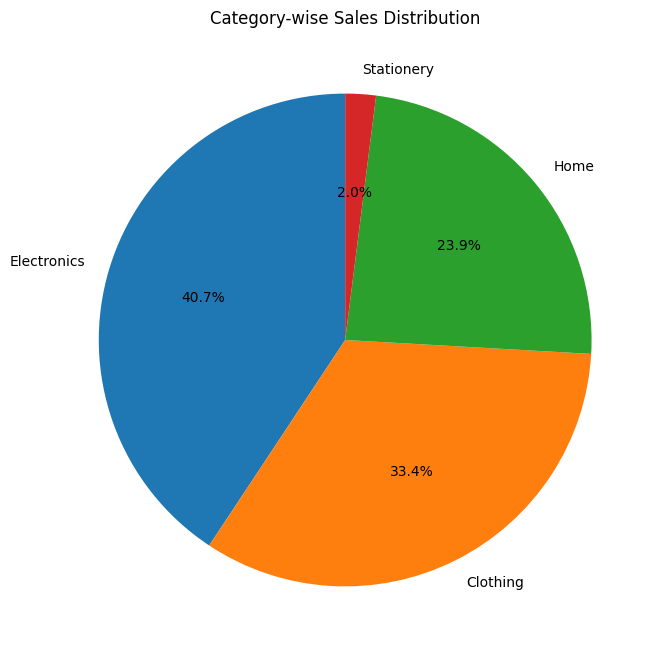

In [32]:
plt.figure(figsize=(8, 8))

plt.pie(
    category_sales.values,
    labels=category_sales.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Category-wise Sales Distribution")

plt.show()